<a href="https://colab.research.google.com/github/FABYG6/DL_Redes_Neuronales_Basicas/blob/main/GUIA_REDES_NEURONALES_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Preparar el entorno: importar librerías

import math
import random
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


In [2]:
# 2. Fijar la semilla y seleccionar CPU o GPU

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)


PyTorch: 2.11.0+cpu
Dispositivo: cpu


In [3]:
# 3. Crear una función que genere rostros sintéticos

def synthetic_face(identity, variant, size=64):
    rng = random.Random(identity * 1000 + variant)
    img = Image.new('L', (size, size), color=230)
    d = ImageDraw.Draw(img)

    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ][identity]

    eye_dx, eye_y, eye_r, mouth_y, style = params
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    d.ellipse(
        (10+jx, 7+jy, 54+jx, 59+jy),
        fill=185 + identity*10,
        outline=60,
        width=2
    )

    cx = 32 + jx
    ey = eye_y + jy
    for ex in (cx-eye_dx//2, cx+eye_dx//2):
        d.ellipse(
            (ex-eye_r//4, ey-eye_r//4,
             ex+eye_r//4, ey+eye_r//4),
            fill=30
        )

    d.line(
        (cx, ey+4, cx-2, ey+14, cx+2, ey+14),
        fill=70,
        width=2
    )

    if style % 2 == 0:
        d.arc(
            (20+jx, mouth_y-6+jy, 44+jx, mouth_y+8+jy),
            start=10, end=170, fill=40, width=2
        )
    else:
        d.arc(
            (20+jx, mouth_y-2+jy, 44+jx, mouth_y+12+jy),
            start=190, end=350, fill=40, width=2
        )

    if style == 1:
        d.line((18+jx, 15+jy, 46+jx, 15+jy),
               fill=40, width=3)
    if style == 2:
        d.ellipse((24+jx, 44+jy, 40+jx, 49+jy),
                  outline=40, width=2)
    if style == 3:
        d.line((15+jx, 28+jy, 49+jx, 28+jy),
               fill=90, width=1)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.default_rng(
        identity*100 + variant
    ).normal(0, 3, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return arr


In [4]:
# 4. Construir el dataset pedagógico

N_ID = 4
N_PER = 12
images = []
labels = []

for ident in range(N_ID):
    for variant in range(N_PER):
        images.append(synthetic_face(ident, variant))
        labels.append(ident)

images = np.stack(images)
labels = np.array(labels)

print('Forma:', images.shape)
print('Etiquetas:', labels.shape)
print('Rango:', images.min(), images.max())


Forma: (48, 64, 64)
Etiquetas: (48,)
Rango: 20 241


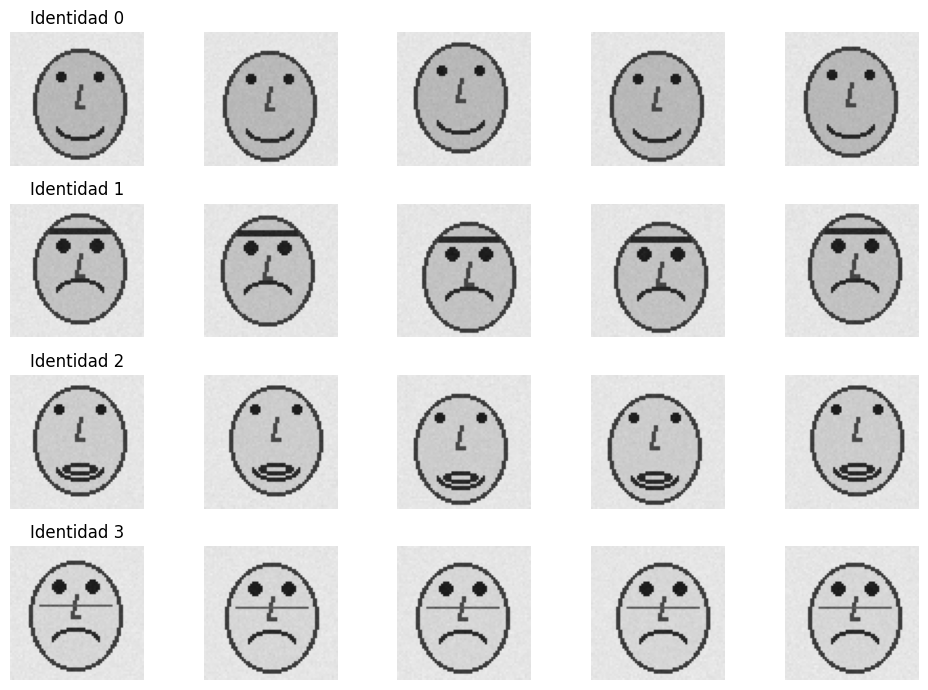

In [5]:
# 5. Visualizar ejemplos del dataset

fig, axes = plt.subplots(N_ID, 5, figsize=(10, 7))

for i in range(N_ID):
    idx = np.where(labels == i)[0][:5]

    for j, k in enumerate(idx):
        axes[i, j].imshow(
            images[k],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[i, j].axis('off')

        if j == 0:
            axes[i, j].set_title(f'Identidad {i}')

plt.tight_layout()
plt.show()


In [6]:
#6. Convertir las imágenes a tensores de PyTorch

X = torch.tensor(images, dtype=torch.float32)
X = X.unsqueeze(1) / 255.0

y = torch.tensor(labels, dtype=torch.long)

print('X:', X.shape)
print('y:', y.shape)
print('Rango X:', float(X.min()), float(X.max()))


X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango X: 0.0784313753247261 0.9450980424880981


In [7]:
# 7. Crear el Dataset de tripletas Anchor–Positive–Negative

class TripletFaces(Dataset):
    def __init__(self, X, y, triplets_per_epoch=400):
        self.X = X
        self.y = y
        self.n = triplets_per_epoch

        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }
        self.classes = list(self.by_class)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        a_class = random.choice(self.classes)

        other_classes = [
            c for c in self.classes
            if c != a_class
        ]
        n_class = random.choice(other_classes)

        a_idx, p_idx = random.sample(
            self.by_class[a_class], 2
        )
        n_idx = random.choice(
            self.by_class[n_class]
        )

        return (
            self.X[a_idx],
            self.X[p_idx],
            self.X[n_idx],
            a_class,
            n_class
        )


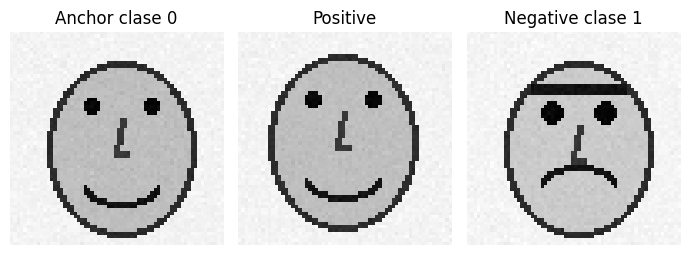

In [8]:
# 8. Crear y observar una tripleta

trip = TripletFaces(X, y, triplets_per_epoch=400)

a, p, n, ca, cn = trip[0]

fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))

for tensor_img, title, axis in [
    (a, f'Anchor clase {ca}', ax[0]),
    (p, 'Positive', ax[1]),
    (n, f'Negative clase {cn}', ax[2])
]:
    axis.imshow(tensor_img.squeeze(), cmap='gray')
    axis.set_title(title)
    axis.axis('off')

plt.tight_layout()
plt.show()


In [9]:
# 9. Construir el encoder de embeddings

class Encoder(nn.Module):
    def __init__(self, emb_dim=64):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.fc = nn.Linear(32 * 4 * 4, emb_dim)

    def forward(self, x):
        z = self.features(x)
        z = z.flatten(1)
        z = self.fc(z)
        z = F.normalize(z, p=2, dim=1)
        return z


In [10]:
# 10. Instanciar el encoder y probar un embedding

model = Encoder(emb_dim=64).to(DEVICE)

print(model)

with torch.no_grad():
    example_embedding = model(
        X[:2].to(DEVICE)
    )

print(
    'Embedding de ejemplo:',
    example_embedding.shape
)


Encoder(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (fc): Linear(in_features=512, out_features=64, bias=True)
)
Embedding de ejemplo: torch.Size([2, 64])


In [11]:
# 11. Preparar DataLoader, Triplet Loss y optimizador

loader = DataLoader(
    trip,
    batch_size=32,
    shuffle=True
)

criterion = nn.TripletMarginLoss(
    margin=0.8,
    p=2
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)


In [12]:
# 12. Entrenar el modelo con Triplet Loss

losses = []

for epoch in range(18):
    model.train()
    total = 0
    count = 0

    for a, p, n, _, _ in loader:
        a = a.to(DEVICE)
        p = p.to(DEVICE)
        n = n.to(DEVICE)

        za = model(a)
        zp = model(p)
        zn = model(n)

        loss = criterion(za, zp, zn)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item() * a.size(0)
        count += a.size(0)

    mean_loss = total / count
    losses.append(mean_loss)

    if epoch in [0, 1, 2, 5, 10, 17]:
        print(
            f'Época {epoch+1:02d} | '
            f'loss={mean_loss:.4f}'
        )


Época 01 | loss=0.3981
Época 02 | loss=0.0266
Época 03 | loss=0.0024
Época 06 | loss=0.0000
Época 11 | loss=0.0001
Época 18 | loss=0.0000


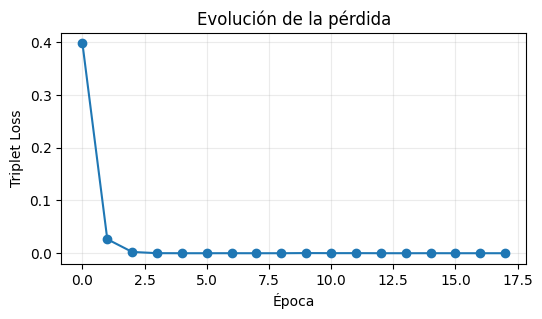

In [13]:
# 13. Graficar la evolución de Triplet Loss

plt.figure(figsize=(6, 3))
plt.plot(losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la pérdida')
plt.grid(alpha=.25)
plt.show()


In [14]:
# 14. Extraer embeddings de todas las imágenes

model.eval()

with torch.no_grad():
    Z = model(
        X.to(DEVICE)
    ).cpu()

print('Forma de Z:', Z.shape)


Forma de Z: torch.Size([48, 64])


Distancia positiva media: 0.1275
Distancia negativa media: 1.5803


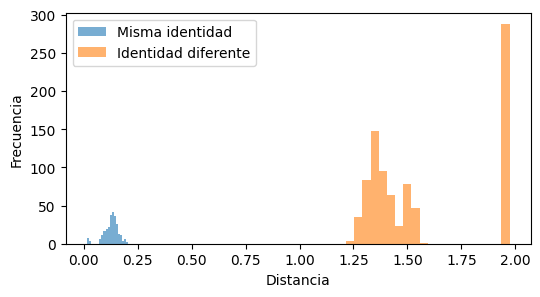

In [15]:
# 15. Comparar distancias positivas y negativas

pos = []
neg = []

for i in range(len(X)):
    for j in range(i + 1, len(X)):
        distance = torch.dist(
            Z[i], Z[j]
        ).item()

        if labels[i] == labels[j]:
            pos.append(distance)
        else:
            neg.append(distance)

print(
    'Distancia positiva media:',
    round(float(np.mean(pos)), 4)
)
print(
    'Distancia negativa media:',
    round(float(np.mean(neg)), 4)
)

plt.figure(figsize=(6, 3))
plt.hist(
    pos, bins=20, alpha=.6,
    label='Misma identidad'
)
plt.hist(
    neg, bins=20, alpha=.6,
    label='Identidad diferente'
)
plt.legend()
plt.xlabel('Distancia')
plt.ylabel('Frecuencia')
plt.show()


In [16]:
# 16. Implementar One-shot Learning

refs = {
    c: np.where(labels == c)[0][0]
    for c in range(N_ID)
}

queries = [
    i for i in range(len(X))
    if i not in refs.values()
]

correct = 0

for i in queries:
    dists = {
        c: torch.dist(
            Z[i], Z[idx]
        ).item()
        for c, idx in refs.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_one = correct / len(queries)

print(
    'Accuracy One-shot:',
    round(acc_one, 4),
    f'({correct}/{len(queries)})'
)


Accuracy One-shot: 1.0 (44/44)


In [17]:
#  17. Implementar Few-shot Learning

ref_ids = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}

prototypes = {}

for c, idx in ref_ids.items():
    proto = Z[idx].mean(
        0, keepdim=True
    )
    proto = F.normalize(
        proto, p=2, dim=1
    )
    prototypes[c] = proto.squeeze(0)

query_ids = [
    i for i in range(len(X))
    if all(
        i not in ids
        for ids in ref_ids.values()
    )
]

correct = 0

for i in query_ids:
    dists = {
        c: torch.dist(
            Z[i], proto
        ).item()
        for c, proto in prototypes.items()
    }

    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_few = correct / len(query_ids)

print(
    'Accuracy Few-shot:',
    round(acc_few, 4),
    f'({correct}/{len(query_ids)})'
)
print(
    'Comparación -> One-shot:',
    round(acc_one, 4),
    '| Few-shot:',
    round(acc_few, 4)
)


Accuracy Few-shot: 1.0 (36/36)
Comparación -> One-shot: 1.0 | Few-shot: 1.0


In [18]:
# 18. Definir un umbral pedagógico de verificación

threshold = (
    float(np.mean(pos)) +
    float(np.mean(neg))
) / 2

print(
    'Umbral pedagógico:',
    round(threshold, 4)
)

def verify(i, j):
    distance = torch.dist(
        Z[i], Z[j]
    ).item()

    same_identity = distance < threshold
    return distance, same_identity

same = np.where(labels == 0)[0][:2]

diff = (
    np.where(labels == 0)[0][0],
    np.where(labels == 1)[0][0]
)

for pair in [tuple(same), diff]:
    distance, ok = verify(*pair)
    result = 'MISMA' if ok else 'DIFERENTE'

    print(
        pair,
        'dist=', round(distance, 4),
        '=>', result
    )


Umbral pedagógico: 0.8539
(np.int64(0), np.int64(1)) dist= 0.17 => MISMA
(np.int64(0), np.int64(12)) dist= 1.4229 => DIFERENTE


In [ ]:
# 19. Comprender por qué este experimento no demuestra Zero-shot real

# No se requiere código nuevo en este paso.
# El modelo fue entrenado con las mismas cuatro identidades
# sintéticas usadas posteriormente en las pruebas.
# Por tanto, esta práctica NO demuestra zero-shot facial real.


In [23]:
# 20. Preparar la carga de fotografías propias o autorizadas

from pathlib import Path

def load_authorized_faces(
    root='/content/rostros',
    size=(64, 64)
):
    root = Path(root)
    imgs = []
    labs = []
    names = []

    if not root.exists():
        print('Aún no existe', root)
        return None, None, None

    persons = sorted([
        p for p in root.iterdir()
        if p.is_dir()
    ])

    for label, person in enumerate(persons):
        names.append(person.name)

        for fp in sorted(person.glob('*')):
            if fp.suffix.lower() not in {
                '.jpg', '.jpeg', '.png', '.webp'
            }:
                continue

            img = Image.open(fp)
            img = img.convert('L').resize(size)

            imgs.append(
                np.array(img, dtype=np.uint8)
            )
            labs.append(label)

    if not imgs:
        print('No se encontraron imágenes.')
        return None, None, names

    Xr = torch.tensor(
        np.stack(imgs),
        dtype=torch.float32
    ).unsqueeze(1) / 255.0

    yr = torch.tensor(
        labs,
        dtype=torch.long
    )

    print('Personas:', names)
    print('Xr:', Xr.shape, 'yr:', yr.shape)

    return Xr, yr, names


In [24]:
# 21. Organizar las carpetas y cargar imágenes autorizadas

# Estructura sugerida:
# /content/rostros/
#   persona_01/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg
#   persona_02/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg

Xr, yr, names = load_authorized_faces(
    '/content/rostros'
)


Aún no existe /content/rostros


In [22]:
# Práctica complementaria con fotografías reales
# 1. Comprobar que el modelo de la práctica anterior sigue disponible

print('Modelo disponible:', 'model' in globals())
print('DEVICE disponible:', 'DEVICE' in globals())

if 'model' not in globals() or 'DEVICE' not in globals():
    print('Debes ejecutar primero la práctica principal de Redes Neuronales V.')
else:
    print('Podemos continuar con fotografías reales.')


Modelo disponible: True
DEVICE disponible: True
Podemos continuar con fotografías reales.


In [25]:
# 2. Importar las librerías necesarias para fotografías reales

import os
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
import torch.nn.functional as F

from google.colab import files

print('Librerías cargadas correctamente')


Librerías cargadas correctamente


In [26]:
# 3. Crear una carpeta limpia para el experimento

ruta_base = '/content/rostros'

if os.path.exists(ruta_base):
    shutil.rmtree(ruta_base)

os.makedirs('/content/rostros/persona_01', exist_ok=True)
os.makedirs('/content/rostros/persona_02', exist_ok=True)

print('Carpetas preparadas:')
print('/content/rostros/persona_01')
print('/content/rostros/persona_02')


Carpetas preparadas:
/content/rostros/persona_01
/content/rostros/persona_02


In [28]:
# 4. Cargar tres fotografías de Persona 1

print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 1')

fotos_persona1 = files.upload()

if len(fotos_persona1) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona1))

for nombre, contenido in fotos_persona1.items():
    ruta = '/content/rostros/persona_01/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 1 guardadas:', len(fotos_persona1))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 1


Saving Alcaraz2.jpg to Alcaraz2.jpg
Saving Alcaraz3.jpg to Alcaraz3.jpg
ADVERTENCIA: se esperaban 3 archivos y se cargaron 2
Fotos de Persona 1 guardadas: 2


In [29]:
# 5. Cargar tres fotografías de Persona 2

print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 2')

fotos_persona2 = files.upload()

if len(fotos_persona2) != 3:
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona2))

for nombre, contenido in fotos_persona2.items():
    ruta = '/content/rostros/persona_02/' + nombre
    with open(ruta, 'wb') as archivo:
        archivo.write(contenido)

print('Fotos de Persona 2 guardadas:', len(fotos_persona2))


Seleccione EXACTAMENTE 3 fotografías de PERSONA 2


Saving Zverev1.jpg to Zverev1.jpg
Saving Zverev2.jpg to Zverev2.jpg
Saving Zverev3.jpg to Zverev3.jpg
Fotos de Persona 2 guardadas: 3


In [31]:
# 6. Verificar la estructura de las carpetas

total = 0

for carpeta, subcarpetas, archivos in os.walk('/content/rostros'):
    print('\nCarpeta:', carpeta)
    for archivo in archivos:
        print('   ', archivo)
        total += 1

print('\nTotal de archivos encontrados:', total)


Carpeta: /content/rostros

Carpeta: /content/rostros/persona_01
    Alcaraz1.jpg
    Alcaraz2.jpg
    Alcaraz3.jpg

Carpeta: /content/rostros/persona_02
    Zverev1.jpg
    Zverev2.jpg
    Zverev3.jpg

Total de archivos encontrados: 6


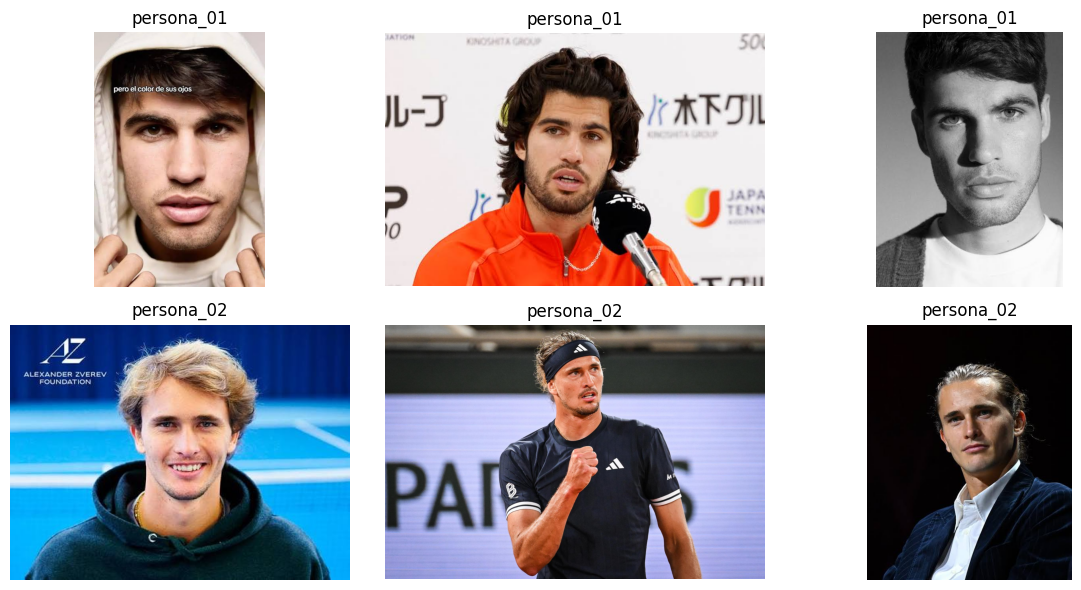

In [32]:
# 7. Visualizar las seis fotografías originales

carpetas = [
    '/content/rostros/persona_01',
    '/content/rostros/persona_02'
]

plt.figure(figsize=(12, 6))
posicion = 1

for carpeta in carpetas:
    persona = os.path.basename(carpeta)

    for archivo in sorted(os.listdir(carpeta)):
        ruta = os.path.join(carpeta, archivo)
        imagen = Image.open(ruta).convert('RGB')

        plt.subplot(2, 3, posicion)
        plt.imshow(imagen)
        plt.title(persona)
        plt.axis('off')

        posicion += 1

plt.tight_layout()
plt.show()


In [33]:
# 8. Crear la función de preprocesamiento

def cargar_rostros(carpeta='/content/rostros', tamano=(64, 64)):
    carpeta = Path(carpeta)

    imagenes = []
    etiquetas = []
    nombres_personas = []

    personas = sorted([p for p in carpeta.iterdir() if p.is_dir()])

    for etiqueta, persona in enumerate(personas):
        nombres_personas.append(persona.name)
        print('Leyendo:', persona.name)

        for archivo in sorted(persona.glob('*')):
            if archivo.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.webp'}:
                continue

            imagen = Image.open(archivo).convert('L')
            imagen = ImageOps.fit(imagen, tamano)
            imagen = np.array(imagen, dtype=np.uint8)

            imagenes.append(imagen)
            etiquetas.append(etiqueta)

    Xr = torch.tensor(np.stack(imagenes), dtype=torch.float32)
    Xr = Xr.unsqueeze(1) / 255.0

    yr = torch.tensor(etiquetas, dtype=torch.long)

    return Xr, yr, nombres_personas


In [35]:
# 9. Convertir las seis fotografías a tensores

Xr, yr, nombres = cargar_rostros('/content/rostros')

print(' Personas encontradas:', nombres)
print('Forma de las imágenes:', Xr.shape)
print('Etiquetas:', yr)


Leyendo: persona_01
Leyendo: persona_02
 Personas encontradas: ['persona_01', 'persona_02']
Forma de las imágenes: torch.Size([6, 1, 64, 64])
Etiquetas: tensor([0, 0, 0, 1, 1, 1])


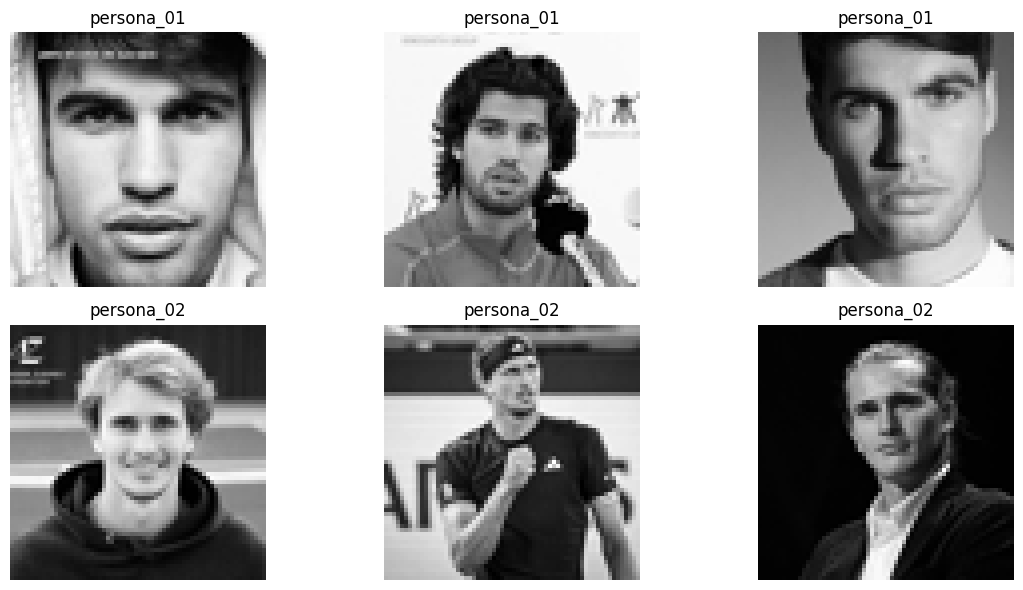

In [36]:
# 10. Visualizar las fotografías ya procesadas

plt.figure(figsize=(12, 6))

for i in range(len(Xr)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Xr[i].squeeze(), cmap='gray')
    plt.title(nombres[yr[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.show()


In [37]:
# 11. Seleccionar Anchor, Positive y Negative

anchor = Xr[0]       # Persona 1
positive = Xr[1]     # Persona 1
negative = Xr[3]     # Persona 2

print('Anchor:', anchor.shape)
print('Positive:', positive.shape)
print('Negative:', negative.shape)


Anchor: torch.Size([1, 64, 64])
Positive: torch.Size([1, 64, 64])
Negative: torch.Size([1, 64, 64])


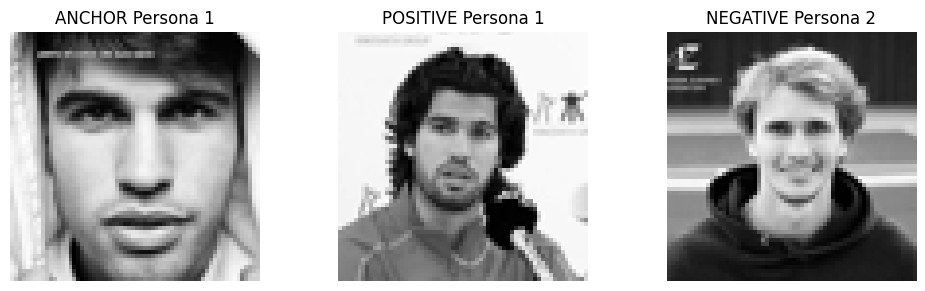

In [40]:
# 12. Visualizar el triple real

plt.figure(figsize=(10, 3))

plt.subplot(1, 3, 1)
plt.imshow(anchor.squeeze(), cmap='gray')
plt.title('ANCHOR Persona 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(positive.squeeze(), cmap='gray')
plt.title('POSITIVE Persona 1')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(negative.squeeze(), cmap='gray')
plt.title('NEGATIVE Persona 2')
plt.axis('off')

plt.tight_layout()
plt.show()


In [42]:
# 14. Observar algunos valores de los embeddings

# Ponemos el modelo en modo evaluación y calculamos los embeddings
model.eval()
with torch.no_grad():
    # Agregamos una dimensión de batch .unsqueeze(0) para poder pasarlas por el modelo
    embedding_anchor = model(anchor.unsqueeze(0).to(DEVICE)).cpu()
    embedding_positive = model(positive.unsqueeze(0).to(DEVICE)).cpu()
    embedding_negative = model(negative.unsqueeze(0).to(DEVICE)).cpu()

print('Primeros 10 valores del Anchor:')
print(embedding_anchor[0][:10])

print('\nPrimeros 10 valores del Positive:')
print(embedding_positive[0][:10])

print('\nPrimeros 10 valores del Negative:')
print(embedding_negative[0][:10])

Primeros 10 valores del Anchor:
tensor([ 0.0440,  0.2046, -0.0811, -0.0167,  0.0505,  0.0585, -0.3696,  0.0837,
        -0.0957, -0.1410])

Primeros 10 valores del Positive:
tensor([ 0.0206,  0.1702, -0.0941, -0.1077,  0.2290, -0.0554, -0.2438,  0.1357,
         0.0673, -0.0356])

Primeros 10 valores del Negative:
tensor([ 0.0700,  0.1157, -0.1093, -0.0266,  0.1601,  0.0308, -0.2978,  0.2409,
        -0.0439, -0.1066])


In [43]:
# 15. Normalizar los embeddings

embedding_anchor_norm = F.normalize(embedding_anchor, p=2, dim=1)
embedding_positive_norm = F.normalize(embedding_positive, p=2, dim=1)
embedding_negative_norm = F.normalize(embedding_negative, p=2, dim=1)

print('Embeddings normalizados correctamente')


Embeddings normalizados correctamente


In [44]:
# 16. Calcular distancia euclidiana

distancia_AP = torch.dist(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

distancia_AN = torch.dist(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

print('Distancia misma persona:', round(distancia_AP, 4))
print('Distancia personas diferentes:', round(distancia_AN, 4))


Distancia misma persona: 0.9006
Distancia personas diferentes: 0.4847


In [45]:
# 17. Interpretar automáticamente las distancias

if distancia_AP < distancia_AN:
    print('RESULTADO:')
    print('La red acerca correctamente las imágenes de la misma persona.')
else:
    print('RESULTADO:')
    print('La red NO logró separar correctamente estas fotografías.')


RESULTADO:
La red NO logró separar correctamente estas fotografías.


In [46]:
# 18. Calcular similitud coseno

similitud_AP = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

similitud_AN = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

print('Similitud misma persona:', round(similitud_AP, 4))
print('Similitud personas diferentes:', round(similitud_AN, 4))


Similitud misma persona: 0.5945
Similitud personas diferentes: 0.8825


In [47]:
# 19. Generar embeddings normalizados para las seis fotografías

model.eval()

with torch.no_grad():
    embeddings = model(Xr.to(DEVICE))
    embeddings = F.normalize(embeddings, p=2, dim=1)

print('Embeddings generados correctamente')
print('Tamaño:', embeddings.shape)


Embeddings generados correctamente
Tamaño: torch.Size([6, 64])


In [48]:
# 20. Identificar las posiciones de cada persona

indices_p1 = torch.where(yr == 0)[0]
indices_p2 = torch.where(yr == 1)[0]

print('Fotos Persona 1:', indices_p1)
print('Fotos Persona 2:', indices_p2)


Fotos Persona 1: tensor([0, 1, 2])
Fotos Persona 2: tensor([3, 4, 5])


In [49]:
# 21. Construir el prototipo de Persona 1

referencias_p1 = embeddings[indices_p1[:2]]

prototipo_p1 = referencias_p1.mean(
    dim=0,
    keepdim=True
)

prototipo_p1 = F.normalize(
    prototipo_p1,
    p=2,
    dim=1
)

print('Prototipo Persona 1:', prototipo_p1.shape)


Prototipo Persona 1: torch.Size([1, 64])


In [50]:
# 22. Construir el prototipo de Persona 2

referencias_p2 = embeddings[indices_p2[:2]]

prototipo_p2 = referencias_p2.mean(
    dim=0,
    keepdim=True
)

prototipo_p2 = F.normalize(
    prototipo_p2,
    p=2,
    dim=1
)

print('Prototipo Persona 2:', prototipo_p2.shape)


Prototipo Persona 2: torch.Size([1, 64])


In [51]:
# 23. Probar la tercera fotografía de Persona 1

consulta_p1 = embeddings[indices_p1[2]].unsqueeze(0)

sim_p1_p1 = F.cosine_similarity(
    consulta_p1,
    prototipo_p1
).item()

sim_p1_p2 = F.cosine_similarity(
    consulta_p1,
    prototipo_p2
).item()

print('FOTO REAL: Persona 1')
print('Similitud con Persona 1:', round(sim_p1_p1, 4))
print('Similitud con Persona 2:', round(sim_p1_p2, 4))

if sim_p1_p1 > sim_p1_p2:
    prediccion_p1 = 'Persona 1'
else:
    prediccion_p1 = 'Persona 2'

print('Predicción:', prediccion_p1)


FOTO REAL: Persona 1
Similitud con Persona 1: 0.9078
Similitud con Persona 2: 0.9065
Predicción: Persona 1


In [52]:
# 24. Probar la tercera fotografía de Persona 2

consulta_p2 = embeddings[indices_p2[2]].unsqueeze(0)

sim_p2_p1 = F.cosine_similarity(
    consulta_p2,
    prototipo_p1
).item()

sim_p2_p2 = F.cosine_similarity(
    consulta_p2,
    prototipo_p2
).item()

print('FOTO REAL: Persona 2')
print('Similitud con Persona 1:', round(sim_p2_p1, 4))
print('Similitud con Persona 2:', round(sim_p2_p2, 4))

if sim_p2_p2 > sim_p2_p1:
    prediccion_p2 = 'Persona 2'
else:
    prediccion_p2 = 'Persona 1'

print('Predicción:', prediccion_p2)


FOTO REAL: Persona 2
Similitud con Persona 1: 0.9069
Similitud con Persona 2: 0.9156
Predicción: Persona 2


In [54]:
# 25. Construir el resumen de la prueba Few-shot

print('=' * 45)
print('PRUEBA FEW-SHOT')
print('=' * 45)

print('CASO 1')
print('Real: Persona 1')
print('Predicción:', prediccion_p1)
print('Resultado:', 'CORRECTO' if prediccion_p1 == 'Persona 1' else 'INCORRECTO')

print('CASO 2')
print('Real: Persona 2')
print('Predicción:', prediccion_p2)
print('Resultado:', 'CORRECTO' if prediccion_p2 == 'Persona 2' else 'INCORRECTO')


PRUEBA FEW-SHOT
CASO 1
Real: Persona 1
Predicción: Persona 1
Resultado: CORRECTO
CASO 2
Real: Persona 2
Predicción: Persona 2
Resultado: CORRECTO


In [55]:
# 26. Calcular la precisión de la prueba

aciertos = 0

if prediccion_p1 == 'Persona 1':
    aciertos += 1

if prediccion_p2 == 'Persona 2':
    aciertos += 1

precision = aciertos / 2

print('Aciertos:', aciertos, 'de 2')
print('Precisión:', round(precision * 100, 2), '%')


Aciertos: 2 de 2
Precisión: 100.0 %


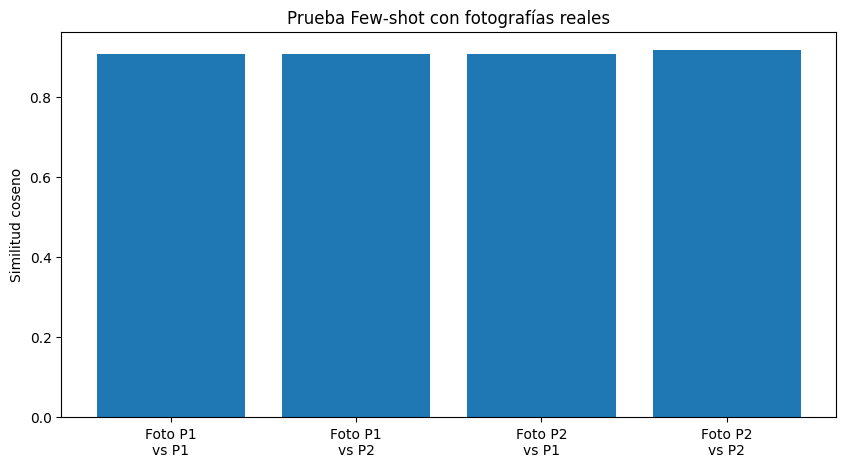

In [58]:
# 27. Graficar las cuatro similitudes Few-shot

valores = [
    sim_p1_p1,
    sim_p1_p2,
    sim_p2_p1,
    sim_p2_p2
]

nombres_grafica = [
    'Foto P1\nvs P1',
    'Foto P1\nvs P2',
    'Foto P2\nvs P1',
    'Foto P2\nvs P2'
]

plt.figure(figsize=(10, 5))
plt.bar(nombres_grafica, valores)
plt.ylabel('Similitud coseno')
plt.title('Prueba Few-shot con fotografías reales')
plt.show()

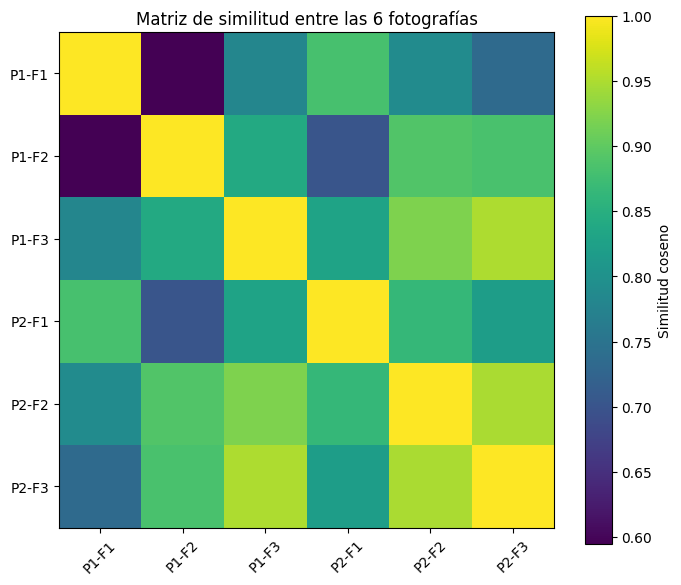

In [59]:
# 28. Construir una matriz de similitud de las seis fotografías

matriz = embeddings @ embeddings.T
matriz_np = matriz.detach().cpu().numpy()

plt.figure(figsize=(7, 6))
plt.imshow(matriz_np)
plt.colorbar(label='Similitud coseno')

etiquetas = [
    'P1-F1', 'P1-F2', 'P1-F3',
    'P2-F1', 'P2-F2', 'P2-F3'
]

plt.xticks(range(6), etiquetas, rotation=45)
plt.yticks(range(6), etiquetas)
plt.title('Matriz de similitud entre las 6 fotografías')
plt.tight_layout()
plt.show()
